<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/heeyeon/advanced/heeyeon/session02/%EB%94%A5%EB%9F%AC%EB%8B%9D%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. CNN 기초
1-1. 픽셀, 채널, 색공간

픽셀

이미지를 이루는 가장 작은 점
각 픽셀은 숫자 하나를 가짐 (보통 0~255)
컴퓨터에게 이미지는 숫자 묶음

기본 단위 2차원 배열 세로x가로로 표현 - 28*28

채널

픽셀 하나에 들어 있는 값의 개수, 이미지의 색상 정보 구성 목적


색공간

    Grayscal 밝기만 표현, 색 구분 x
0은 검정, 255는 흰색, 채널이 1인 이유는 세션 때  좀더 자세히 공부

    RGB 빨강, 초록, 파랑을 섞어 색을 만듦
딥러닝 입력에 가장 많이 쓴다고 한다 때로 '깊이'라고도 부른다.

---

1-2. CNN의 개념과 구조

이미지 처리에 특화된 신경망  
픽셀 위치 관계를 유지한 채 특징을 뽑는다.   
필터가 스스로 중요한 특징을 학습함 중요물체를 구분.   


구조

입력
→ [Convolution Layer, Flatten, 분류 (Classification)]


이미지를 인식하기 위한 모델은 크게 이미지의 특징을 학습하는 부분과, 학습한 특징을 바탕으로 어떤 이미지인지 분류하는 부분으로 구성

앞쪽 층은 단순한 특징을 봄 (선, 모서리) 또한
뒤쪽 층은 복잡한 형태를 봄

---
2. MLP vs. CNN
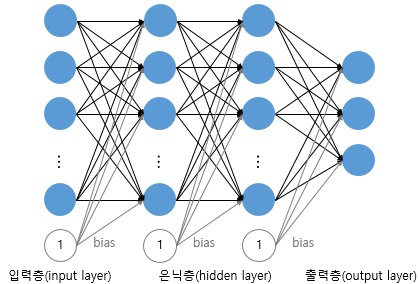

    2-1. MLP의 한계
MLP는 이미지를 한 줄로 펼쳐서 넣는다.즉 입력 데이터를 1차원 배열로 펼치는데, 그럴 시

픽셀 사이 위치 관계가 사라지는 문제가 생김.
(가중치 수가 너무 많아짐)

-> 계산이 무겁고 과적합되기 쉽다. 따라서 이미지의 특징을 학습하는 과정이 추가된다는 것이 차이점이다. 이전에는 물체 위치가 조금만 바뀌어도 다르게 인식하기 때문이다.


  2-2. CNN의 해결 방법
  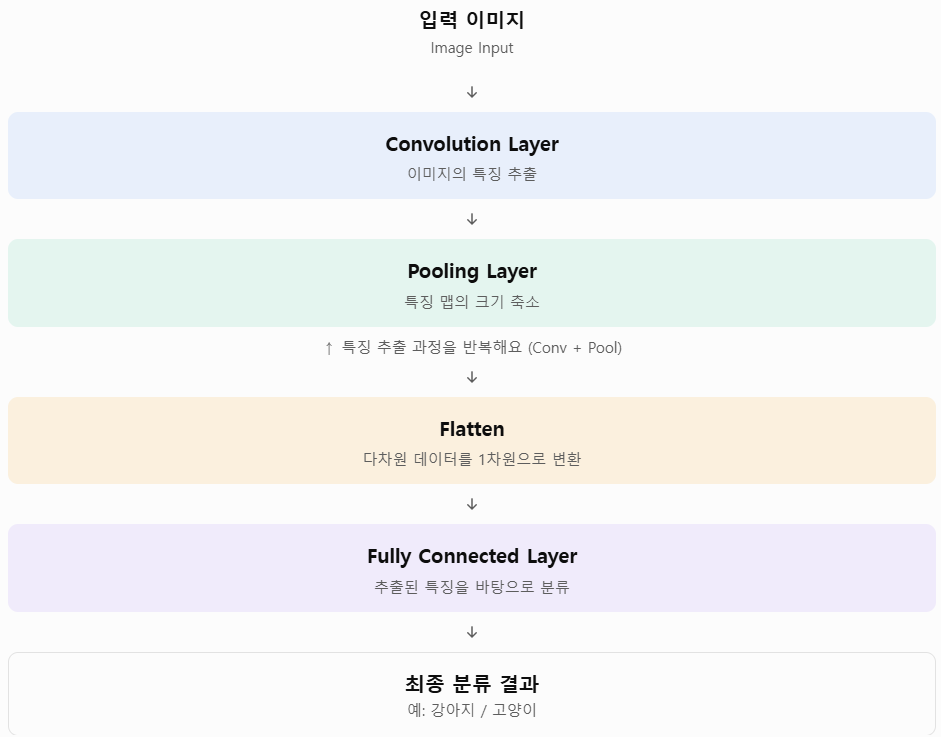


---
3. 합성곱과 풀링

  3-1. Convolution Layer
    Convolution Layer는 입력 이미지 전체를 일정한 크기의 필터(Filter)로 훑으면서 이미지의 특징을 추출하고 학습하는 계층

연산 과정 요약
필터(커널)는 작은 가중치 표
필터가 이미지 위를 슬라이딩
겹친 부분끼리 곱하고 모두 더하기
그 결과를 모은 것이 특징 맵/
(학습되는 것은 필터 안의 숫자)

필터 깊이 = 입력 채널 수
필터 개수 = 출력 채널 수

더 공부한 것->
*출력 크기 공식*

출력 크기 = (N + 2P − F) / S + 1
N: 입력 크기 / F: 필터 크기 / P: 패딩 / S: 스트라이드

*파라미터 수 공식*
(필터 높이 *필터 너비 * 입력 채널 + 1) * 필터 개수

cnn은 여러 필터로 특징 추출, 세로선과 가로선 반응 필터의 역할이 다르낟.  이를 이용해 이미지에 포함된 다양한 정보를 학습

---
3-2. Padding
Convolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입, 즉 이미지 테두리에 값을 채우는 것

보통 0을 채우는 제로 패딩을 이용하는
이유

합성곱을 하면 크기가 줄어들고 정보도 잘 반영되기 때문!!



3-3. Stride
필터가 한 번에 움직이는 칸 수임, stride 1, 2와 같은 식으로.

스트라이드가 크면
-> 출력이 작아짐, 일부 위치를 건너 뛰며 역산하기에
계산이 줄어듦 -> 따라서 세부 정보는 일부 놓칠 수 있음



3-4. Pooling

특징 맵 크기를 줄이는 것
작은 구역마다 대표값 하나만 남김

종류
Max Pooling: 지정된 영역세서 가장 큰 값을 남김 (가장 많이 씀)
Average Pooling: 지정영역 안 평균값을 남김

특징
차원 축소로 계산량 감소: 학습할 가중치가 없음
노이즈 영향 완화, 채널 수는 그대로, 위치 변화 강건성이 있으므로 가로, 세로만 줄어듦  

그러나 정보가 소실되는 위험이 있다.


(솔직히 원리 이해는 글로만 읽어서 잘 되지 않는 것 같습니다. 세션 때 공부 열심히 하겠습니다 )

---
4. 이미지 딥러닝 응용

4-1. 이미지 분류
이미지 전체를 보고 정답 하나를 고름
클래스별 확률을 출력함  


대표 모델: AlexNet ResNet, vggnet
| 모델명 | 특징 요약 | 주의사항 |
| --- | --- | --- |
| **AlexNet** | 비교적 단순한 구조, 초기 CNN 모델들 | 작은 데이터셋이나 학습 개념 설명용 |
| **VGG** | 복잡한 블록 구조 적용 | 계산량 증대, 메모리 요구 높음 |
| **ResNet** | Residual 연결  → 매우 깊은 네트워크 가능 | 과적합 주의, batch size / regularization 조절 필요 |
| **Vision Transformer (ViT)** | Transformer 구조 응용  | 이미지와 순차 처리 모델의 결합, 대규모 데이터 필요 |


4-2. 객체 탐지
이미지안에 객체가 뭐가 있는지, 종류와 이미지 치 학습
위치는 네모 박스(바운딩 박스)로 표시함
여러 물체를 한 번에 찾을 수 있음


구분	2-Stage	1-Stage
방식	후보 찾고 → 분류	한 번에 예측
특징	정확함, 느림	빠름
IoU: 예측 박스와 정답 박스가 겹치는 정도
NMS: 겹치는 박스 중 하나만 남김
mAP: 탐지 성능 평가 지표
Classification Head : 객체의 종류 예측  
Regression Head : 객체의 위치 좌표 예측

4-3. 이미지 캡셔닝
이미지의 내용을 자연어 문장으로 표현하는 작업
이미지 처리와 언어 처리를 합친 문제임
"한 사람이 도로에서 자전거 타고 있습니다 "

구조
CNN이 이미지 특징을 뽑음 (인코더)-> 사람, 자전거
RNN/LSTM이 문장을 만듦 (디코더)-> 단어 순서대로 생성
이후 어텐션을 붙여 성능을 높임

---
5. 순차 데이터
    데이터의 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터


정형 데이터 vs. 순차 데이터
구분	정형 데이터,	순차 데이터
순서	바꿔도 상관없음,	바꾸면 의미가 달라짐
관계	각 행이 따로	앞 값이 뒤 값에 영향 줌
길이	고정,	제각각



---
6. 과거를 기억하는 신경만 RNN


6-1. 구조와 원리
→ 기존신경망과 비교했을 때 가장 큰 차이점은 은닉층에 순환 구조가 존재하는 것!  


은닉 상태는 기억 역할을 함, 은닉층이란 현재 입력 xₜ와 이전 시점의 은닉 상태 hₜ₋₁를 함께 받아 새로운 은닉 상태 hₜ를 만드는 곳  

h_t = tanh(W_x · x_t + W_h · h_(t-1) + b)
y_t = W_y · h_t

- 현재 입력과 이전 은닉 상태를 같이 씀
- 모든 시점이 같은 가중치를 씀
- 시간 순으로 펼치면 같은 셀이 이어진 모양임
- 학습은 BPTT로 함 (시간을 거슬러 역전파)

6-2. 아키텍처 종류

종류	입력 → 출력	쓰임
---
One-to-One	1 → 1	일반 분류
Many-to-One	여러 개 → 1	감성 분석, 다음 값 예측
Many-to-Many (동기)	시점마다 출력	단어별 태깅


6-3. 한계점
 시간에 따른 역전파, 기울기 소실, 기울기 폭주, 느린 훈련 시간, 장기 의존성 문제 하나로 결국 귀결이 된다. 그래서 중요 정보 오래 기억하는....

→  LSTM, GRU가 등장함

---

7. LSTM & GRU
7-1. LSTM

핵심

-셀 상태라는 장기 기억 통로를 따로 둠
-게이트로 정보 흐름을 조절함
-게이트 값은 0~1 사이
-0이면 막고, 1이면 통과시킴

| 구분 | 역할 |
| --- | --- |
| 셀 상태 (Cell State, c) | 장기 기억 |
| 은닉 상태 (Hidden State, h) | 단기 기억 & 출력 |


Forget Gate: 옛 기억 중 무엇을 버릴지 정함
Input Gate: 새 정보를 얼마나 저장할지 정함
Output Gate: 무엇을 출력할지 정함

셀 상태는 덧셈으로 업데이트됨
그래서 기울기가 잘 전달됨
긴 시퀀스도 기억할 수 있음


7-2. GRU

핵심

LSTM을 단순하게 만든 모델, 셀 상태가 없고, 은닉 상태 하나만 쓰면서 게이트는 2개뿐  


게이트 2개   

Reset Gate: 옛 정보를 얼마나 무시할지 정함  
Update Gate: 옛 정보와 새 정보의 비율을 정함  


짧고 단순한 데이터 → RNN도 가능
길고 복잡한 데이터 → LSTM
데이터가 적거나 빨라야 함 → GRU


---
## 8. Seq2Seq 문장을 받아 문장을 출력하다...  

8-1. 구조와 원리  
순서 있는 입력을  받아 순서 있는 출력을 만듦
번역, 요약, 챗봇처럼 .   


    인코더

입력을 처음부터 끝까지 읽음

입력 전체를 요약한 값

    디코더

컨텍스트 벡터를 받아 시작함


8-2. 한계

    병목 현상
입력 전체를 고정 크기 벡터 하나에 담음
입력이 길면 정보가 빠짐


    장기 의존성 문제
아주 긴 입력에서는 여전히 앞 내용을 잊음
느린 속도
RNN 기반이라 순서대로 계산함

    오류 누적
앞에서 틀리면 뒤까지 영향을 줌

    -> 해결책: 어텐션

디코더가 매 단계 인코더 전체를 다시 보고, 지금 필요한 부분에 집중함-> 이후 Transformer로 발전!!
